In [16]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('diabetes_data.csv',encoding='latin1')

In [3]:
df.head(5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
0,2,115.863387,56.410731,24.336736,94.385783,26.455940,0.272682,20.100494,0
1,2,92.490122,70.615520,23.443591,138.652426,23.910167,0.665160,44.912281,0
2,1,88.141469,63.262618,23.404364,149.358082,21.948250,0.676022,48.247873,1
3,2,108.453101,67.793632,20.751580,108.751638,24.209304,0.289636,42.749868,0
4,1,127.849443,94.725685,22.603078,25.269987,32.997477,0.601315,32.797789,0


In [4]:
X = df.drop('Diagnosis',axis=1)

In [5]:
y = df['Diagnosis']

In [6]:
df.shape

(1000, 9)

In [7]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Diagnosis,0


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
X.shape, y.shape

((1000, 8), (1000,))

In [12]:
df.corr(numeric_only=True)['Diagnosis'].sort_values(ascending=False)

,Diagnosis
Diagnosis,1.000000
DiabetesPedigreeFunction,0.060549
Insulin,0.035411
BloodPressure,0.010349
SkinThickness,-0.000014
Pregnancies,-0.001484
Glucose,-0.004971
BMI,-0.033336
Age,-0.044726


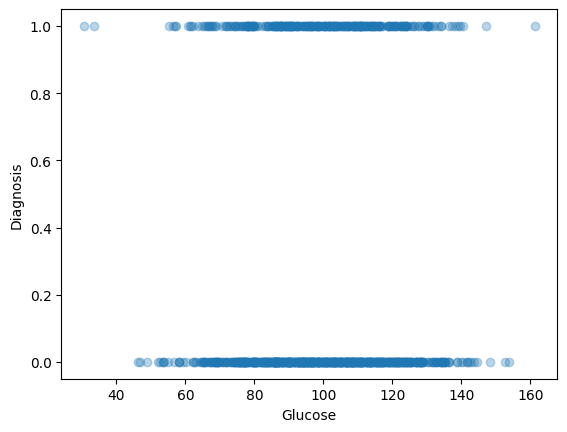

In [15]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.scatter(df['Glucose'], df['Diagnosis'], alpha=0.3)
plt.xlabel('Glucose')
plt.ylabel('Diagnosis')
plt.show()

In [18]:
zero_cols = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]
zero_cols

['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

In [20]:
(df[zero_cols] == 0).sum()
# X[zero_cols] = X[zero_cols].replace(0, np.nan)

,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0


In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model  = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier",LogisticRegression(max_iter=1000))
])

model.fit(X_train,y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier', LogisticRegression(max_iter=1000))])

In [31]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test) [ : ,1]
print("y pred = " ,y_pred,"\n y_proba = ", y_proba)

y pred =  [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0] 
 y_proba =  [0.38494669 0.33171596 0.28861263 0.35529674 0.2533454  0.2968013
 0.31396672 0.25448384 0.34527647 0.30146279 0.22756227 0.26744302
 0.27816226 0.33422856 0.34266739 0.320671   0.25470991 0.28934947
 0.27746864 0.32606597 0.36465854 0.31856428 0.35344638 0.38726954
 0.35744241 0.30849466 0.32776499 0.33618507 0.24182931 0.34612354
 0.25457317 0.3260082  0.39324457 0.25617771 0.21300085 0.32864142
 0.29042486 0.28894725 0.30507963 0.37621192 0.38441499 0.37630499
 0.25071103 0.2476914  0.25997161 0.30944856 0.40874106 0.28059102
 0.24446929 0.29908461 0.30645446 0

In [32]:
from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report,roc_auc_score)

print("accuracy : ", accuracy_score(y_test,y_pred))
print("ROC-AUC",roc_auc_score(y_test,y_proba))
print("confusion matrix : ",confusion_matrix(y_test,y_pred))
print("classification report : ",classification_report(y_test,y_pred))

accuracy :  0.695
ROC-AUC 0.5100837362896569
confusion matrix :  [[139   0]
 [ 61   0]]
classification report :                precision    recall  f1-score   support

           0       0.69      1.00      0.82       139
           1       0.00      0.00      0.00        61

    accuracy                           0.69       200
   macro avg       0.35      0.50      0.41       200
weighted avg       0.48      0.69      0.57       200



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [33]:
print("Target distribution:")
print(y.value_counts())

print("\nTarget dtype:")
print(y.dtype)

print("\nPredicted classes:")
print(pd.Series(y_pred).value_counts())

print("\nPredicted probabilities:")
print(pd.Series(y_proba).describe())

print("\nCoefficients:")
print(pd.Series(
    model.named_steps["classifier"].coef_[0],
    index=X.columns
).sort_values())

Target distribution:
Diagnosis
0    694
1    306
Name: count, dtype: int64

Target dtype:
int64

Predicted classes:
0    200
Name: count, dtype: int64

Predicted probabilities:
count    200.000000
mean       0.309040
std        0.050782
min        0.183824
25%        0.270355
50%        0.308298
75%        0.343320
max        0.446941
dtype: float64

Coefficients:
Age                        -0.157836
BMI                        -0.075845
Pregnancies                -0.008117
SkinThickness              -0.008071
Glucose                    -0.007950
BloodPressure               0.053876
Insulin                     0.078950
DiabetesPedigreeFunction    0.153036
dtype: float64


In [34]:
print(df.head())
print(df.describe())

   Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
0            2  115.863387      56.410731      24.336736   94.385783   
1            2   92.490122      70.615520      23.443591  138.652426   
2            1   88.141469      63.262618      23.404364  149.358082   
3            2  108.453101      67.793632      20.751580  108.751638   
4            1  127.849443      94.725685      22.603078   25.269987   

         BMI  DiabetesPedigreeFunction        Age  Diagnosis  
0  26.455940                  0.272682  20.100494          0  
1  23.910167                  0.665160  44.912281          0  
2  21.948250                  0.676022  48.247873          1  
3  24.209304                  0.289636  42.749868          0  
4  32.997477                  0.601315  32.797789          0  
       Pregnancies      Glucose  BloodPressure  SkinThickness      Insulin  \
count  1000.000000  1000.000000    1000.000000    1000.000000  1000.000000   
mean      1.771000    99.440607  

In [35]:
y.value_counts()

,count
Diagnosis,
0,694
1,306


In [37]:
pd.Series(y_proba).describe()

,0
count,200.000000
mean,0.309040
std,0.050782
min,0.183824
25%,0.270355
50%,0.308298
75%,0.343320
max,0.446941


In [45]:
min(list(X["Glucose"]))

30.571402161232346

In [46]:
min(list(X["Age"]))

-0.979803578151646

In [48]:
min(list(X["Insulin"]))

-165.3100326101158

In [50]:
(df<0).sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,127
BMI,0
DiabetesPedigreeFunction,0
Age,2
Diagnosis,0


In [51]:
# 127/1000 insulin records have < 0, which isnt medically possible. Dataset has error.

In [56]:
df2 = pd.read_csv('data-01.txt',sep='\t',encoding='latin1')

In [57]:
df2.head()

,04-21-1991,9:09,58,100
0,04-21-1991,9:09,33,9
1,04-21-1991,9:09,34,13
2,04-21-1991,17:08,62,119
3,04-21-1991,17:08,33,7
4,04-21-1991,22:51,48,123


In [58]:
df2.shape

(942, 4)

In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               1000 non-null   int64  
 1   Glucose                   1000 non-null   float64
 2   BloodPressure             1000 non-null   float64
 3   SkinThickness             1000 non-null   float64
 4   Insulin                   1000 non-null   float64
 5   BMI                       1000 non-null   float64
 6   DiabetesPedigreeFunction  1000 non-null   float64
 7   Age                       1000 non-null   float64
 8   Diagnosis                 1000 non-null   int64  
dtypes: float64(7), int64(2)
memory usage: 70.4 KB


In [ ]:
#shape says 4 cols and info says 9 cols. Wrong data

In [63]:
print("columns:", df2.columns.tolist())

columns: ['04-21-1991', '9:09', '58', '100']
